<a href="https://colab.research.google.com/github/sanya-6976/ml-interview-practise-dataset-projects/blob/main/06_customer_segmentation_kmeans_pca.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Shape: (200, 5)


,CustomerID,Gender,Age,Annual_Income_k,Spending_Score
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40



--- Summary Stats (Notice Different Scales!) ---


,Age,Annual_Income_k,Spending_Score
count,200.00,200.00,200.00
mean,38.85,60.56,50.20
std,13.97,26.26,25.82
min,18.00,15.00,1.00
25%,28.75,41.50,34.75
50%,36.00,61.50,50.00
75%,49.00,78.00,73.00
max,70.00,137.00,99.00


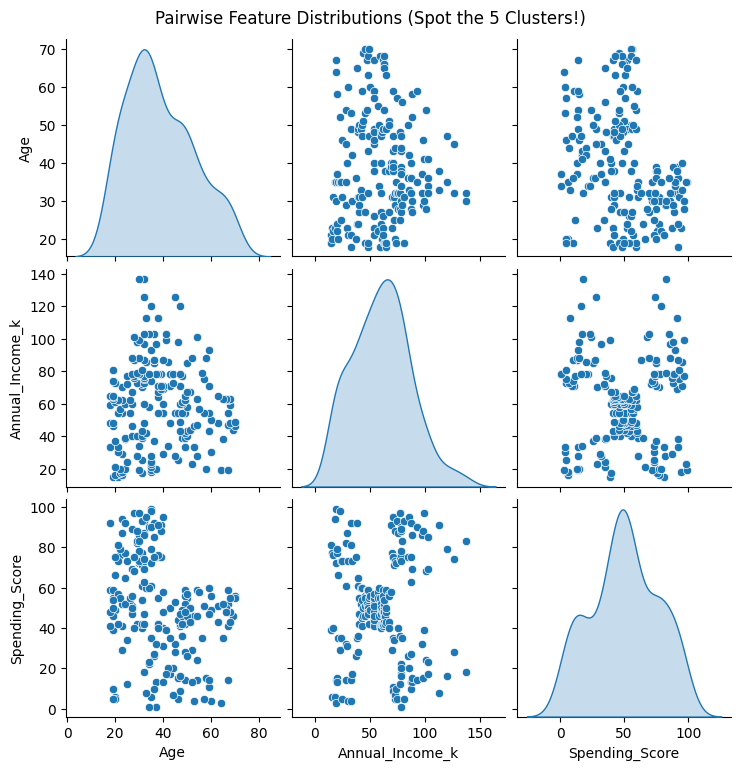

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load Mall Customers dataset (200 customers)
url = "https://raw.githubusercontent.com/SteffiPeTaffy/machineLearningAZ/master/Machine%20Learning%20A-Z%20Template%20Folder/Part%204%20-%20Clustering/Section%2025%20-%20Hierarchical%20Clustering/Mall_Customers.csv"
df = pd.read_csv(url)

# Rename columns cleanly
df.columns = ['CustomerID', 'Gender', 'Age', 'Annual_Income_k', 'Spending_Score']
print("Shape:", df.shape)
display(df.head())

print("\n--- Summary Stats (Notice Different Scales!) ---")
display(df[['Age', 'Annual_Income_k', 'Spending_Score']].describe().round(2))

# Pairplot to visually spot natural customer groupings
sns.pairplot(df[['Age', 'Annual_Income_k', 'Spending_Score']], diag_kind='kde')
plt.suptitle('Pairwise Feature Distributions (Spot the 5 Clusters!)', y=1.02)
plt.show()

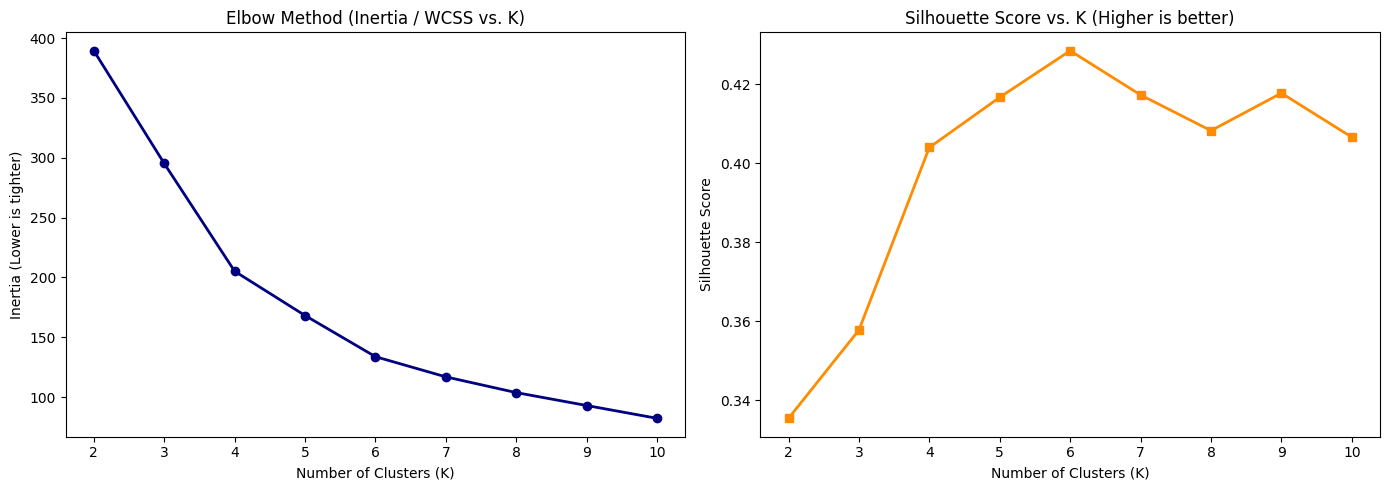

K= 2 | Inertia: 389.39 | Silhouette Score: 0.3355
K= 3 | Inertia: 295.21 | Silhouette Score: 0.3578
K= 4 | Inertia: 205.23 | Silhouette Score: 0.4040
K= 5 | Inertia: 168.25 | Silhouette Score: 0.4166
K= 6 | Inertia: 133.87 | Silhouette Score: 0.4284
K= 7 | Inertia: 117.01 | Silhouette Score: 0.4172
K= 8 | Inertia: 103.87 | Silhouette Score: 0.4082
K= 9 | Inertia:  93.09 | Silhouette Score: 0.4177
K=10 | Inertia:  82.39 | Silhouette Score: 0.4066


In [2]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# 1. Select behavioral & demographic features and apply StandardScaler
features = ['Age', 'Annual_Income_k', 'Spending_Score']
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[features])

# 2. Evaluate K = 2 to 10 using Inertia (Elbow) & Silhouette Score
k_values = range(2, 11)
inertias = []
sil_scores = []

for k in k_values:
    km = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=42)
    labels = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)
    sil_scores.append(silhouette_score(X_scaled, labels))

# 3. Plot Elbow Curve & Silhouette Score side-by-side
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(k_values, inertias, marker='o', color='navy', lw=2)
axes[0].set_title('Elbow Method (Inertia / WCSS vs. K)')
axes[0].set_xlabel('Number of Clusters (K)')
axes[0].set_ylabel('Inertia (Lower is tighter)')
axes[0].set_xticks(k_values)

axes[1].plot(k_values, sil_scores, marker='s', color='darkorange', lw=2)
axes[1].set_title('Silhouette Score vs. K (Higher is better)')
axes[1].set_xlabel('Number of Clusters (K)')
axes[1].set_ylabel('Silhouette Score')
axes[1].set_xticks(k_values)

plt.tight_layout()
plt.show()

for k, iner, sil in zip(k_values, inertias, sil_scores):
    print(f"K={k:2d} | Inertia: {iner:6.2f} | Silhouette Score: {sil:.4f}")

Total Variance Explained by 2 Principal Components: 77.57%



Age       Annual_Income_k       Spending_Score      
        count  mean           count  mean          count  mean
Cluster                                                       
0          45  56.3              45  54.3             45  49.1
1          39  26.8              39  57.1             39  48.1
2          33  41.9              33  88.9             33  17.0
3          39  32.7              39  86.5             39  82.1
4          23  25.0              23  25.3             23  77.6
5          21  45.5              21  26.3             21  19.4

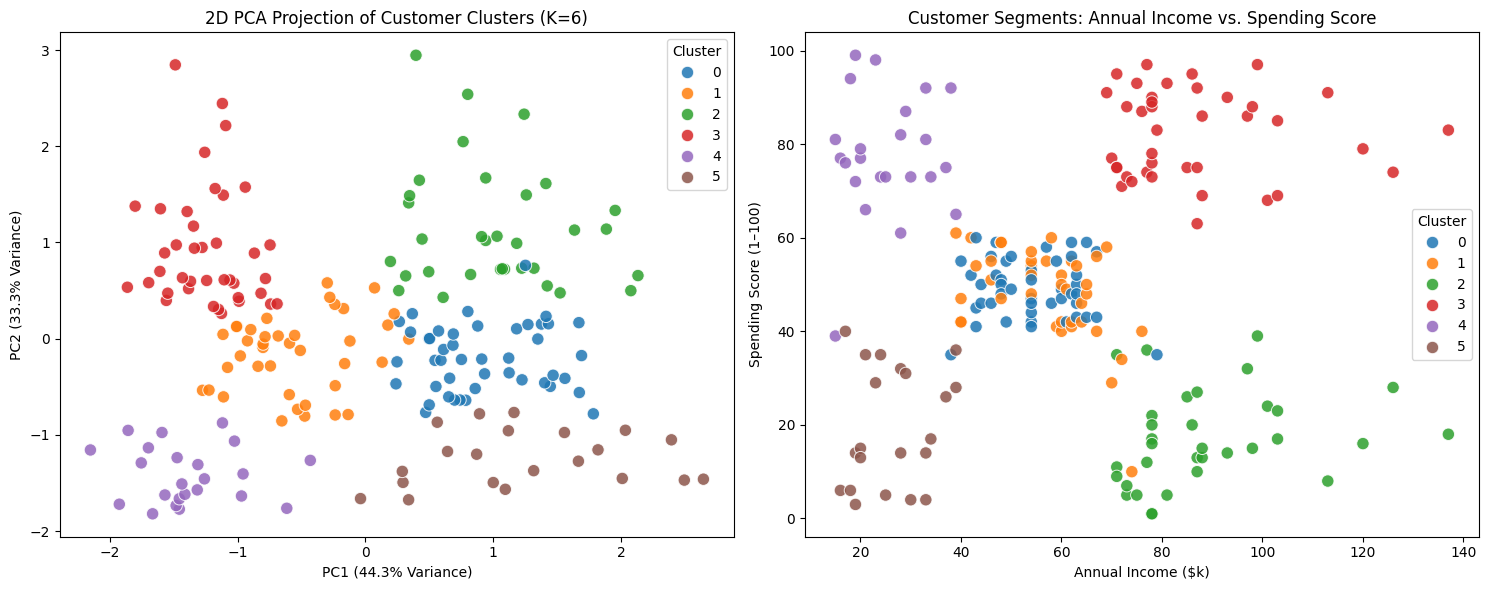

In [3]:
from sklearn.decomposition import PCA

# 1. Fit final K-Means model (using optimal K=6 from Silhouette peak)
optimal_k = 6
kmeans_final = KMeans(n_clusters=optimal_k, init='k-means++', n_init=10, random_state=42)
df['Cluster'] = kmeans_final.fit_predict(X_scaled)

# 2. Project 3D scaled features into 2D using PCA for visualization
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)
df['PC1'] = X_pca[:, 0]
df['PC2'] = X_pca[:, 1]

print(f"Total Variance Explained by 2 Principal Components: {pca.explained_variance_ratio_.sum()*100:.2f}%\n")

# 3. Inspect Business Personas (Unscaled Averages per Cluster)
persona_summary = df.groupby('Cluster')[['Age', 'Annual_Income_k', 'Spending_Score']].agg(['count', 'mean']).round(1)
display(persona_summary)

# 4. Visualize PCA Clusters & Income vs. Spending Segmentation
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

sns.scatterplot(
    data=df, x='PC1', y='PC2', hue='Cluster',
    palette='tab10', s=80, alpha=0.85, ax=axes[0]
)
axes[0].set_title(f'2D PCA Projection of Customer Clusters (K={optimal_k})')
axes[0].set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% Variance)')
axes[0].set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% Variance)')

sns.scatterplot(
    data=df, x='Annual_Income_k', y='Spending_Score', hue='Cluster',
    palette='tab10', s=80, alpha=0.85, ax=axes[1]
)
axes[1].set_title('Customer Segments: Annual Income vs. Spending Score')
axes[1].set_xlabel('Annual Income ($k)')
axes[1].set_ylabel('Spending Score (1–100)')

plt.tight_layout()
plt.show()

"I built an unsupervised customer segmentation pipeline on the Mall Customers dataset using Age, Annual Income, and Spending Score. Because K-Means relies on Euclidean distance, I standardized all features with StandardScaler so high-magnitude income values wouldn't dominate distance calculations. Rather than relying solely on the visual Elbow Method, I validated cluster count using the Silhouette Score across $K \in [2, 10]$, identifying the optimal peak at $K = 6$ (Silhouette = 0.428) with k-means++ initialization. Finally, I projected the clusters onto 2D via PCA (~77% variance retained) and profiled unscaled cluster centroids into actionable marketing personas—such as high-income VIPs for loyalty rewards and high-income low-spenders for targeted re-engagement."